<a href="https://colab.research.google.com/github/eparks8/ECGR-5105-Intro-to-ML/blob/main/HW7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 7: Fully Connected Neural Networks for CIFAR-10 Classification

## Imports

In [7]:
# File System
import pathlib
import os
import csv
import datetime as dt
import time

# Data Manipulation
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Model
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import torch.optim as optim

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Google Drive Imports
from google.colab import drive

## Data Preparation

### Data Imports

In [2]:
drive.mount('/content/drive')

# 2. Set your Google Drive dataset folder path and local target path
drive_folder = "/content/drive/MyDrive/Colab Notebooks/Datasets/cifar10_data"
local_folder = "/content/cifar10_data"

# 3. Fast-copy the folder containing the batch files to local memory
!cp -r "$drive_folder" "$local_folder"

print("Local batch files available:")
print(os.listdir(local_folder))

# 3. Define standard normalization transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# 2. Point root to /content/cifar10_data where 'cifar-10-batches-py' sits
train_dataset = torchvision.datasets.CIFAR10(
    root='/content/cifar10_data',
    train=True,
    download=False,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root='/content/cifar10_data',
    train=False,
    download=False,
    transform=transform
)

# 3. Create high-speed DataLoaders streaming directly from RAM/local SSD
train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f"Train dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")


Mounted at /content/drive
Local batch files available:
['cifar-10-batches-py']
Train dataset size: 50000
Test dataset size: 10000


## Problem 1: Fully Connected Neural Network Architecture

### Baseline Classifier

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10, device='cpu'):
    model = model.to(device)
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    total_start_time = time.time()

    for epoch in range(num_epochs):
        epoch_start_time = time.time()

        # Training Phase
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = 100.0 * correct / total

        # Validation Phase
        model.eval()
        running_val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                running_val_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = 100.0 * val_correct / val_total

        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)

        epoch_duration = time.time() - epoch_start_time

        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | "
              f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}% | "
              f"Time: {epoch_duration:.2f}s")

    total_duration = time.time() - total_start_time
    print(f"\nTraining complete in: {total_duration // 60:.0f}m {total_duration % 60:.2f}s")

    return history

In [4]:
base = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(3072, 1024),
    torch.nn.ReLU(),
    torch.nn.Linear(1024, 256),
    torch.nn.ReLU(),
    torch.nn.Linear(256, 10)
)

In [9]:
hist = train_model(base, train_loader, test_loader, torch.nn.CrossEntropyLoss(), optim.Adam(base.parameters(), lr=0.001), num_epochs=30, device=device)

Epoch [1/30] Train Loss: 0.3204, Train Acc: 88.92% | Val Loss: 2.1800, Val Acc: 54.78% | Time: 14.45s
Epoch [2/30] Train Loss: 0.2644, Train Acc: 90.90% | Val Loss: 2.3172, Val Acc: 54.00% | Time: 15.81s
Epoch [3/30] Train Loss: 0.2516, Train Acc: 91.41% | Val Loss: 2.3978, Val Acc: 55.08% | Time: 13.10s
Epoch [4/30] Train Loss: 0.2311, Train Acc: 91.86% | Val Loss: 2.5332, Val Acc: 53.15% | Time: 12.76s
Epoch [5/30] Train Loss: 0.2321, Train Acc: 92.04% | Val Loss: 2.4776, Val Acc: 54.83% | Time: 12.18s
Epoch [6/30] Train Loss: 0.2022, Train Acc: 93.04% | Val Loss: 2.6869, Val Acc: 54.20% | Time: 12.32s
Epoch [7/30] Train Loss: 0.1982, Train Acc: 93.01% | Val Loss: 2.7693, Val Acc: 54.30% | Time: 14.14s
Epoch [8/30] Train Loss: 0.1789, Train Acc: 93.87% | Val Loss: 2.8695, Val Acc: 54.56% | Time: 13.40s
Epoch [9/30] Train Loss: 0.1853, Train Acc: 93.67% | Val Loss: 2.9844, Val Acc: 53.55% | Time: 13.16s
Epoch [10/30] Train Loss: 0.1795, Train Acc: 93.92% | Val Loss: 3.0572, Val Acc: 5

### Increased Depth Classifier

In [10]:
deep_base = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(3072, 1024),
    torch.nn.ReLU(),
    torch.nn.Linear(1024, 512),
    torch.nn.ReLU(),
    torch.nn.Linear(512, 256),
    torch.nn.ReLU(),
    torch.nn.Linear(256, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 10)
)

In [11]:
hist_deep = train_model(deep_base, train_loader, test_loader, torch.nn.CrossEntropyLoss(), optim.Adam(deep_base.parameters(), lr=0.001), num_epochs=25)
# Decline after 20

Epoch [1/25] Train Loss: 1.7004, Train Acc: 39.07% | Val Loss: 1.5216, Val Acc: 46.27% | Time: 25.22s
Epoch [2/25] Train Loss: 1.4504, Train Acc: 48.61% | Val Loss: 1.4371, Val Acc: 49.43% | Time: 26.97s
Epoch [3/25] Train Loss: 1.3190, Train Acc: 53.20% | Val Loss: 1.3739, Val Acc: 52.11% | Time: 25.51s
Epoch [4/25] Train Loss: 1.2211, Train Acc: 56.84% | Val Loss: 1.3417, Val Acc: 52.91% | Time: 25.33s
Epoch [5/25] Train Loss: 1.1177, Train Acc: 60.53% | Val Loss: 1.3417, Val Acc: 53.66% | Time: 27.35s
Epoch [6/25] Train Loss: 1.0294, Train Acc: 63.46% | Val Loss: 1.3429, Val Acc: 53.78% | Time: 26.12s
Epoch [7/25] Train Loss: 0.9367, Train Acc: 66.63% | Val Loss: 1.3792, Val Acc: 54.11% | Time: 25.54s
Epoch [8/25] Train Loss: 0.8447, Train Acc: 69.56% | Val Loss: 1.4168, Val Acc: 53.91% | Time: 26.42s
Epoch [9/25] Train Loss: 0.7676, Train Acc: 72.35% | Val Loss: 1.4476, Val Acc: 55.48% | Time: 24.46s
Epoch [10/25] Train Loss: 0.6835, Train Acc: 75.34% | Val Loss: 1.4636, Val Acc: 5

## Problem 2: Impact of Network Depth and Architecture

### Deep Fully Connected Neural Network


In [12]:
deep_fcnn = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(3072, 2048),
    torch.nn.ReLU(),
    torch.nn.Linear(2048, 1024),
    torch.nn.ReLU(),
    torch.nn.Linear(1024, 768),
    torch.nn.ReLU(),
    torch.nn.Linear(768, 512),
    torch.nn.ReLU(),
    torch.nn.Linear(512, 256),
    torch.nn.ReLU(),
    torch.nn.Linear(256, 192),
    torch.nn.ReLU(),
    torch.nn.Linear(192, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 16),
    torch.nn.ReLU(),
    torch.nn.Linear(16, 10)
)

In [13]:
deep_fcnn_hist = train_model(deep_fcnn, train_loader, test_loader, torch.nn.CrossEntropyLoss(), optim.Adam(deep_fcnn.parameters(), lr=0.001), num_epochs=25)
# Consistent peak at 19-23

Epoch [1/25] Train Loss: 2.0547, Train Acc: 17.65% | Val Loss: 1.9579, Val Acc: 18.13% | Time: 55.76s
Epoch [2/25] Train Loss: 1.9434, Train Acc: 21.38% | Val Loss: 1.9476, Val Acc: 21.97% | Time: 53.89s
Epoch [3/25] Train Loss: 1.8632, Train Acc: 26.44% | Val Loss: 1.8310, Val Acc: 29.35% | Time: 56.61s
Epoch [4/25] Train Loss: 1.7428, Train Acc: 32.79% | Val Loss: 1.7431, Val Acc: 34.03% | Time: 61.96s
Epoch [5/25] Train Loss: 1.5796, Train Acc: 41.87% | Val Loss: 1.5513, Val Acc: 44.90% | Time: 61.51s
Epoch [6/25] Train Loss: 1.4645, Train Acc: 47.15% | Val Loss: 1.5002, Val Acc: 47.42% | Time: 61.29s
Epoch [7/25] Train Loss: 1.3498, Train Acc: 51.94% | Val Loss: 1.4381, Val Acc: 49.98% | Time: 61.52s
Epoch [8/25] Train Loss: 1.2633, Train Acc: 54.76% | Val Loss: 1.4360, Val Acc: 50.25% | Time: 61.64s
Epoch [9/25] Train Loss: 1.1749, Train Acc: 58.33% | Val Loss: 1.4144, Val Acc: 51.49% | Time: 61.78s
Epoch [10/25] Train Loss: 1.0877, Train Acc: 61.28% | Val Loss: 1.4204, Val Acc: 5

### Other Architecture Considerations

#### Models

In [14]:
wide_base = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(3072, 2048),
    torch.nn.ReLU(),
    torch.nn.Linear(2048, 512),
    torch.nn.ReLU(),
    torch.nn.Linear(512, 10)
)

In [15]:
sig_base = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(3072, 1024),
    torch.nn.Sigmoid(),
    torch.nn.Linear(1024, 256),
    torch.nn.Sigmoid(),
    torch.nn.Linear(256, 10)
)

In [16]:
tanh_base = torch.nn.Sequential(
    torch.nn.Flatten(),
    torch.nn.Linear(3072, 1024),
    torch.nn.Tanh(),
    torch.nn.Linear(1024, 256),
    torch.nn.Tanh(),
    torch.nn.Linear(256, 10)
)

#### Training

In [17]:
wide_hist = train_model(wide_base, train_loader, test_loader, torch.nn.CrossEntropyLoss(), optim.Adam(wide_base.parameters(), lr=0.001), num_epochs=50)

Epoch [1/50] Train Loss: 1.6405, Train Acc: 41.79% | Val Loss: 1.4928, Val Acc: 47.37% | Time: 42.44s
Epoch [2/50] Train Loss: 1.4092, Train Acc: 50.31% | Val Loss: 1.4528, Val Acc: 48.99% | Time: 43.37s
Epoch [3/50] Train Loss: 1.2917, Train Acc: 54.39% | Val Loss: 1.3854, Val Acc: 52.12% | Time: 43.68s
Epoch [4/50] Train Loss: 1.1916, Train Acc: 57.84% | Val Loss: 1.3513, Val Acc: 53.33% | Time: 44.59s
Epoch [5/50] Train Loss: 1.0980, Train Acc: 61.15% | Val Loss: 1.3517, Val Acc: 53.64% | Time: 46.29s
Epoch [6/50] Train Loss: 1.0053, Train Acc: 64.33% | Val Loss: 1.3551, Val Acc: 54.30% | Time: 46.03s
Epoch [7/50] Train Loss: 0.9154, Train Acc: 67.78% | Val Loss: 1.3957, Val Acc: 54.72% | Time: 46.26s
Epoch [8/50] Train Loss: 0.8211, Train Acc: 70.79% | Val Loss: 1.4577, Val Acc: 54.27% | Time: 45.77s
Epoch [9/50] Train Loss: 0.7431, Train Acc: 73.86% | Val Loss: 1.5139, Val Acc: 54.25% | Time: 47.26s
Epoch [10/50] Train Loss: 0.6586, Train Acc: 76.61% | Val Loss: 1.5973, Val Acc: 5

In [18]:
sig_hist = train_model(sig_base, train_loader, test_loader, torch.nn.CrossEntropyLoss(), optim.Adam(sig_base.parameters(), lr=0.001), num_epochs=50)

Epoch [1/50] Train Loss: 1.7939, Train Acc: 36.17% | Val Loss: 1.6408, Val Acc: 42.05% | Time: 23.33s
Epoch [2/50] Train Loss: 1.5764, Train Acc: 44.32% | Val Loss: 1.5339, Val Acc: 46.21% | Time: 21.42s
Epoch [3/50] Train Loss: 1.4630, Train Acc: 48.39% | Val Loss: 1.5004, Val Acc: 47.15% | Time: 23.01s
Epoch [4/50] Train Loss: 1.3771, Train Acc: 51.48% | Val Loss: 1.4362, Val Acc: 49.84% | Time: 21.68s
Epoch [5/50] Train Loss: 1.2930, Train Acc: 54.52% | Val Loss: 1.4196, Val Acc: 50.29% | Time: 22.18s
Epoch [6/50] Train Loss: 1.2115, Train Acc: 57.43% | Val Loss: 1.4017, Val Acc: 51.07% | Time: 22.58s
Epoch [7/50] Train Loss: 1.1288, Train Acc: 60.61% | Val Loss: 1.3929, Val Acc: 51.52% | Time: 22.21s
Epoch [8/50] Train Loss: 1.0428, Train Acc: 63.65% | Val Loss: 1.3999, Val Acc: 51.86% | Time: 22.76s
Epoch [9/50] Train Loss: 0.9593, Train Acc: 66.76% | Val Loss: 1.4324, Val Acc: 51.18% | Time: 21.83s
Epoch [10/50] Train Loss: 0.8724, Train Acc: 69.92% | Val Loss: 1.4572, Val Acc: 5

In [19]:
tanh_hist = train_model(tanh_base, train_loader, test_loader, torch.nn.CrossEntropyLoss(), optim.Adam(tanh_base.parameters(), lr=0.001), num_epochs=50)

Epoch [1/50] Train Loss: 1.7534, Train Acc: 38.64% | Val Loss: 1.6199, Val Acc: 43.97% | Time: 21.55s
Epoch [2/50] Train Loss: 1.5674, Train Acc: 45.95% | Val Loss: 1.5694, Val Acc: 46.33% | Time: 23.39s
Epoch [3/50] Train Loss: 1.4599, Train Acc: 49.78% | Val Loss: 1.5038, Val Acc: 47.79% | Time: 21.59s
Epoch [4/50] Train Loss: 1.3774, Train Acc: 52.44% | Val Loss: 1.5097, Val Acc: 48.11% | Time: 23.27s
Epoch [5/50] Train Loss: 1.2974, Train Acc: 55.56% | Val Loss: 1.4835, Val Acc: 48.81% | Time: 21.67s
Epoch [6/50] Train Loss: 1.2328, Train Acc: 57.45% | Val Loss: 1.4963, Val Acc: 48.94% | Time: 22.58s
Epoch [7/50] Train Loss: 1.1614, Train Acc: 59.91% | Val Loss: 1.4905, Val Acc: 49.24% | Time: 22.19s
Epoch [8/50] Train Loss: 1.0865, Train Acc: 62.63% | Val Loss: 1.4968, Val Acc: 49.83% | Time: 21.71s
Epoch [9/50] Train Loss: 1.0185, Train Acc: 65.05% | Val Loss: 1.5183, Val Acc: 49.24% | Time: 23.08s
Epoch [10/50] Train Loss: 0.9405, Train Acc: 67.95% | Val Loss: 1.5427, Val Acc: 4

## Data Analysis and Comparison

### Problem 1a

Training Time:  
Epochs: 30  
Avg. Training Time:

--- Final Base Model Metrics ---
Final Training Loss: 0.1126
Final Validation Loss: 4.1616
Final Training Accuracy: 96.30%
Final Validation Accuracy: 55.26%
-------------------------------



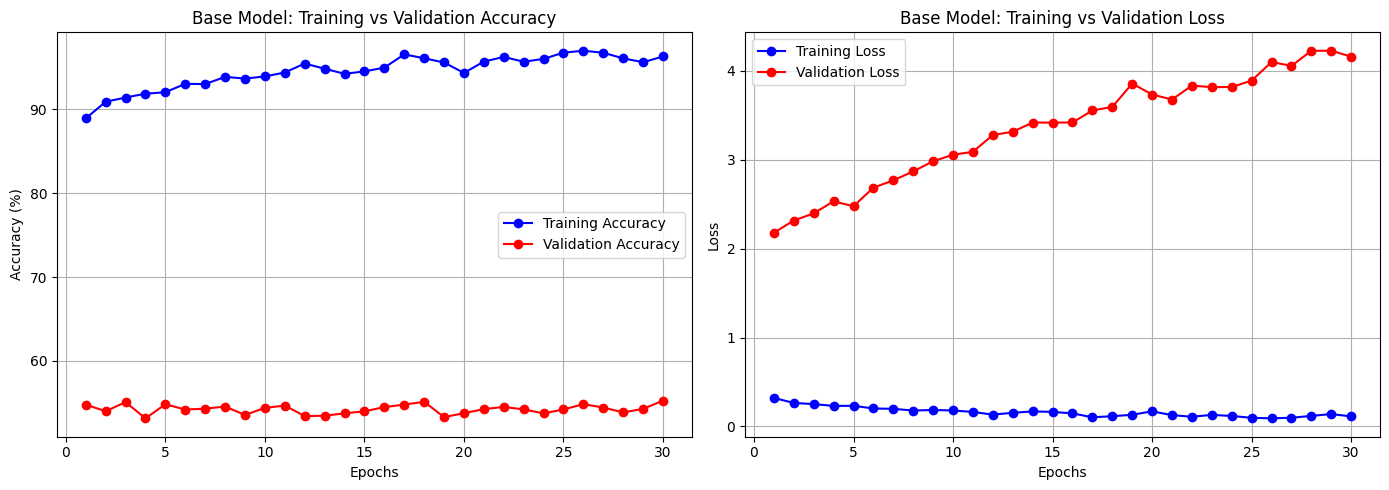

In [20]:
# Final base losses and accuracies
final_train_loss = hist['train_loss'][-1]
final_val_loss = hist['val_loss'][-1]
final_train_acc = hist['train_acc'][-1]
final_val_acc = hist['val_acc'][-1]

print(f"--- Final Base Model Metrics ---")
print(f"Final Training Loss: {final_train_loss:.4f}")
print(f"Final Validation Loss: {final_val_loss:.4f}")
print(f"Final Training Accuracy: {final_train_acc:.2f}%")
print(f"Final Validation Accuracy: {final_val_acc:.2f}%")

epochs = range(1, len(hist['train_loss']) + 1)

plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs, hist['train_acc'], 'bo-', label='Training Accuracy')
plt.plot(epochs, hist['val_acc'], 'ro-', label='Validation Accuracy')
plt.title('Base Model: Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs, hist['train_loss'], 'bo-', label='Training Loss')
plt.plot(epochs, hist['val_loss'], 'ro-', label='Validation Loss')
plt.title('Base Model: Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Problem 1b

--- Final Deep Base Model Metrics ---
Final Training Loss: 0.1540
Final Validation Loss: 3.1370
Final Training Accuracy: 94.66%
Final Validation Accuracy: 53.92%
-------------------------------------



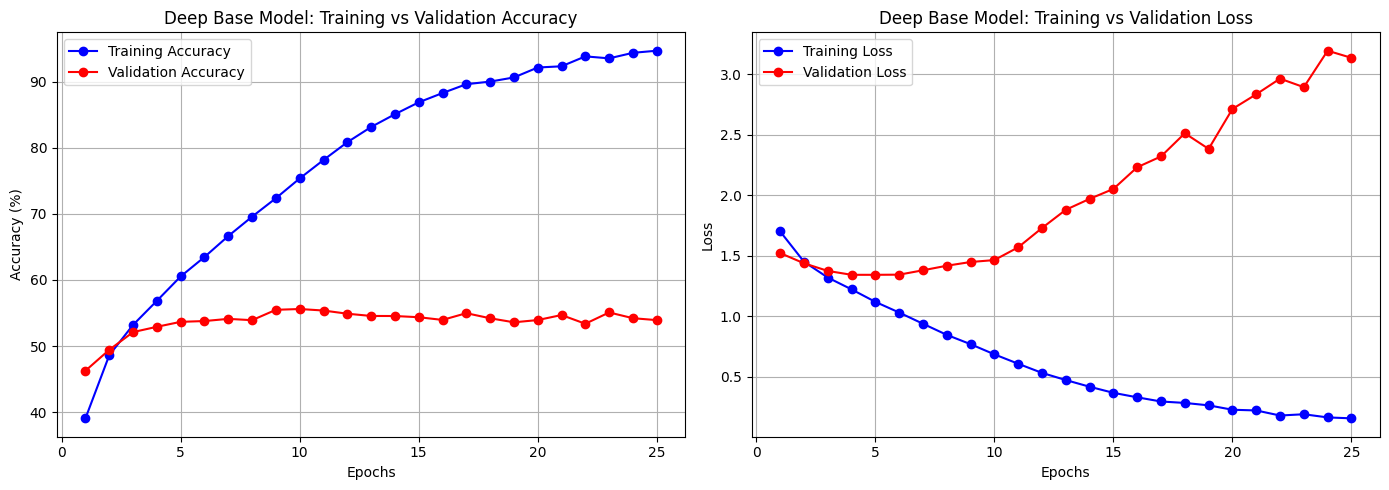

In [21]:
# Final slightly deep losses and accuracies
final_deep_train_loss = hist_deep['train_loss'][-1]
final_deep_val_loss = hist_deep['val_loss'][-1]
final_deep_train_acc = hist_deep['train_acc'][-1]
final_deep_val_acc = hist_deep['val_acc'][-1]

print(f"--- Final Deep Base Model Metrics ---")
print(f"Final Training Loss: {final_deep_train_loss:.4f}")
print(f"Final Validation Loss: {final_deep_val_loss:.4f}")
print(f"Final Training Accuracy: {final_deep_train_acc:.2f}%")
print(f"Final Validation Accuracy: {final_deep_val_acc:.2f}%")
print(f"-------------------------------------\n")

epochs = range(1, len(hist_deep['train_loss']) + 1)

plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs, hist_deep['train_acc'], 'bo-', label='Training Accuracy')
plt.plot(epochs, hist_deep['val_acc'], 'ro-', label='Validation Accuracy')
plt.title('Deep Base Model: Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs, hist_deep['train_loss'], 'bo-', label='Training Loss')
plt.plot(epochs, hist_deep['val_loss'], 'ro-', label='Validation Loss')
plt.title('Deep Base Model: Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Problem 2a

--- Final Deep FCNN Model Metrics ---
Final Training Loss: 0.2579
Final Validation Loss: 2.4392
Final Training Accuracy: 91.40%
Final Validation Accuracy: 52.10%
-------------------------------------



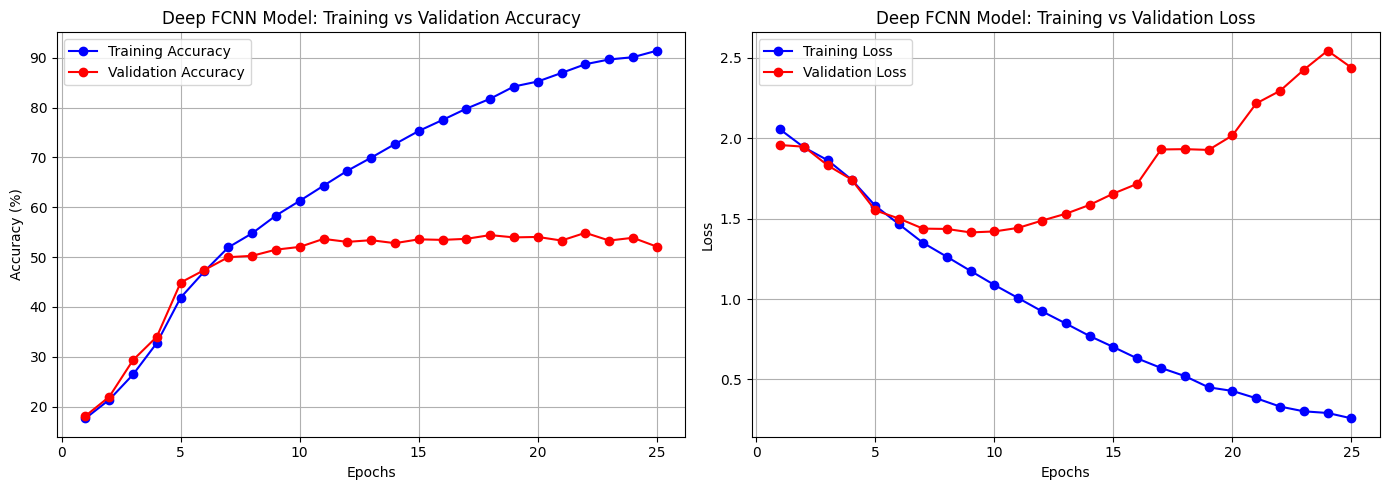

In [22]:
# Final deep losses and accuracies
final_fcnn_train_loss = deep_fcnn_hist['train_loss'][-1]
final_fcnn_val_loss = deep_fcnn_hist['val_loss'][-1]
final_fcnn_train_acc = deep_fcnn_hist['train_acc'][-1]
final_fcnn_val_acc = deep_fcnn_hist['val_acc'][-1]

print(f"--- Final Deep FCNN Model Metrics ---")
print(f"Final Training Loss: {final_fcnn_train_loss:.4f}")
print(f"Final Validation Loss: {final_fcnn_val_loss:.4f}")
print(f"Final Training Accuracy: {final_fcnn_train_acc:.2f}%")
print(f"Final Validation Accuracy: {final_fcnn_val_acc:.2f}%")
print(f"-------------------------------------\n")

epochs = range(1, len(deep_fcnn_hist['train_loss']) + 1)

plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs, deep_fcnn_hist['train_acc'], 'bo-', label='Training Accuracy')
plt.plot(epochs, deep_fcnn_hist['val_acc'], 'ro-', label='Validation Accuracy')
plt.title('Deep FCNN Model: Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs, deep_fcnn_hist['train_loss'], 'bo-', label='Training Loss')
plt.plot(epochs, deep_fcnn_hist['val_loss'], 'ro-', label='Validation Loss')
plt.title('Deep FCNN Model: Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Problem 2b

--- Final Wide Base Model Metrics ---
Final Training Loss: 0.1343
Final Validation Loss: 4.4586
Final Training Accuracy: 95.75%
Final Validation Accuracy: 54.82%
-------------------------------------

--- Final Sigmoid Base Model Metrics ---
Final Training Loss: 0.0581
Final Validation Loss: 3.3766
Final Training Accuracy: 98.27%
Final Validation Accuracy: 48.98%
-------------------------------------

--- Final Tanh Base Model Metrics ---
Final Training Loss: 0.1764
Final Validation Loss: 2.9735
Final Training Accuracy: 93.94%
Final Validation Accuracy: 47.21%
-------------------------------------



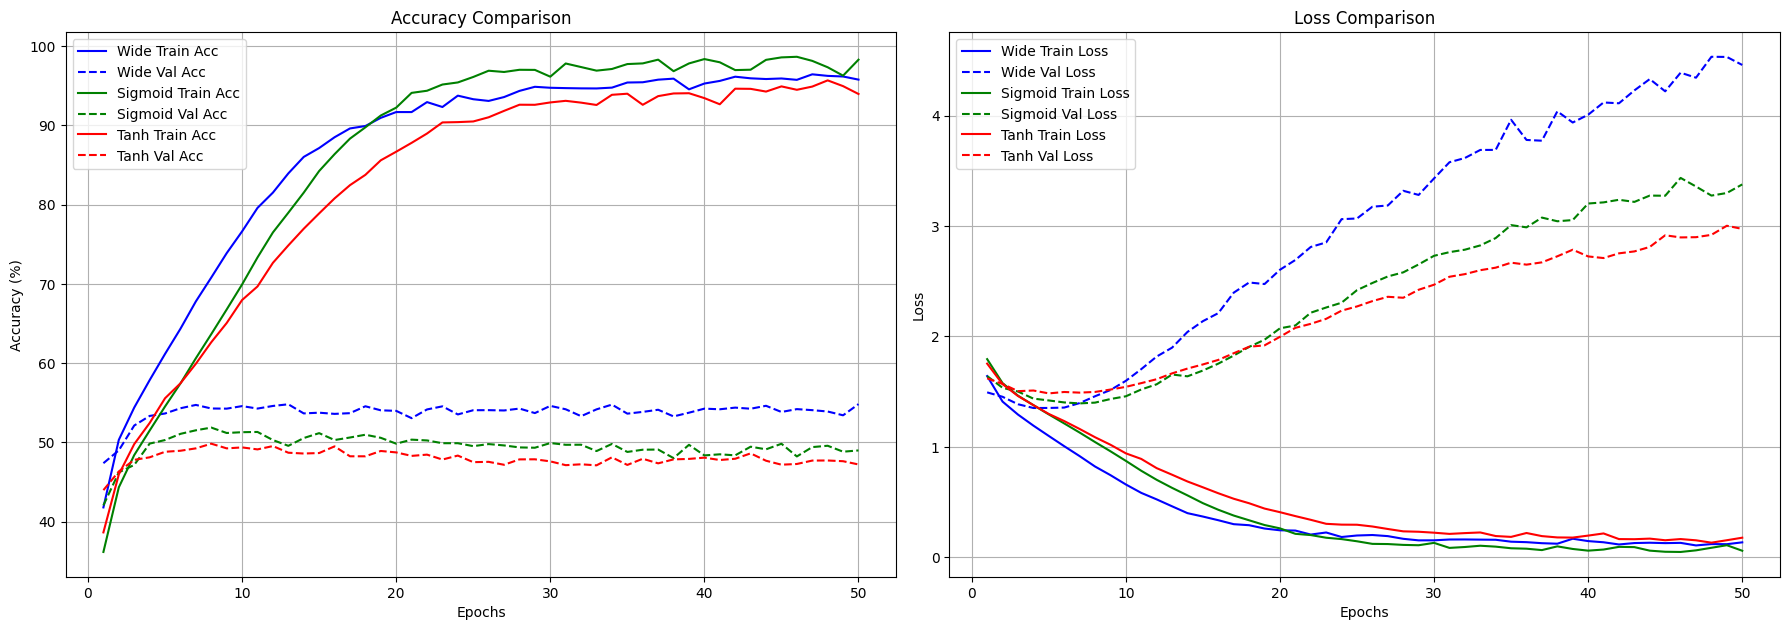

In [23]:
# Final metrics
models_metrics = [
    ("Wide Base Model", wide_hist),
    ("Sigmoid Base Model", sig_hist),
    ("Tanh Base Model", tanh_hist)
]

for name, hist_data in models_metrics:
    final_train_loss = hist_data['train_loss'][-1]
    final_val_loss = hist_data['val_loss'][-1]
    final_train_acc = hist_data['train_acc'][-1]
    final_val_acc = hist_data['val_acc'][-1]

    print(f"--- Final {name} Metrics ---")
    print(f"Final Training Loss: {final_train_loss:.4f}")
    print(f"Final Validation Loss: {final_val_loss:.4f}")
    print(f"Final Training Accuracy: {final_train_acc:.2f}%")
    print(f"Final Validation Accuracy: {final_val_acc:.2f}%")
    print(f"-------------------------------------\n")

plt.figure(figsize=(18, 12))

# Accuracy Comparison
plt.subplot(2, 2, 1)
epochs_wide = range(1, len(wide_hist['train_loss']) + 1)
plt.plot(epochs_wide, wide_hist['train_acc'], 'b-', label='Wide Train Acc')
plt.plot(epochs_wide, wide_hist['val_acc'], 'b--', label='Wide Val Acc')
epochs_sig = range(1, len(sig_hist['train_loss']) + 1)
plt.plot(epochs_sig, sig_hist['train_acc'], 'g-', label='Sigmoid Train Acc')
plt.plot(epochs_sig, sig_hist['val_acc'], 'g--', label='Sigmoid Val Acc')
epochs_tanh = range(1, len(tanh_hist['train_loss']) + 1)
plt.plot(epochs_tanh, tanh_hist['train_acc'], 'r-', label='Tanh Train Acc')
plt.plot(epochs_tanh, tanh_hist['val_acc'], 'r--', label='Tanh Val Acc')
plt.title('Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

# Loss Comparison
plt.subplot(2, 2, 2)
plt.plot(epochs_wide, wide_hist['train_loss'], 'b-', label='Wide Train Loss')
plt.plot(epochs_wide, wide_hist['val_loss'], 'b--', label='Wide Val Loss')
plt.plot(epochs_sig, sig_hist['train_loss'], 'g-', label='Sigmoid Train Loss')
plt.plot(epochs_sig, sig_hist['val_loss'], 'g--', label='Sigmoid Val Loss')
plt.plot(epochs_tanh, tanh_hist['train_loss'], 'r-', label='Tanh Train Loss')
plt.plot(epochs_tanh, tanh_hist['val_loss'], 'r--', label='Tanh Val Loss')
plt.title('Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Trainable Parameters

In [24]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"--- Trainable Parameters Count ---")
print(f"1.a Baseline Model: {count_parameters(base):,}")
print(f"1.b Deep Base Model (4 Hidden Layers): {count_parameters(deep_base):,}")
print(f"2.a Deep FCNN (10 Hidden Layers): {count_parameters(deep_fcnn):,}")
print(f"2.b Experiment 1 - Wide Model: {count_parameters(wide_base):,}")
print(f"2.b Experiment 2 - Sigmoid Model: {count_parameters(sig_base):,}")
print(f"2.b Experiment 3 - Tanh Mod
el: {count_parameters(tanh_base):,}")
print(f"----------------------------------")

--- Trainable Parameters Count ---
1.a Baseline Model: 3,411,722
1.b Deep Base Model (4 Hidden Layers): 3,837,066
2.a Deep FCNN (10 Hidden Layers): 9,789,018
2.b Experiment 1 - Wide Model: 7,347,722
2.b Experiment 2 - Sigmoid Model: 3,411,722
2.b Experiment 3 - Tanh Model: 3,411,722
----------------------------------
